# Phase 2.4 — Financial Feature Analysis: HPG Research

Phân tích 26 feature từ `data/processed/HPG_features_labeled_research.parquet` (VCI Research, `PASS_WITH_LIMITATIONS`). RQ1 dự báo Close(t+1) > Close(t), với X được biết sau Close(t); RQ2 là proxy Open(t+1) đến Open(t+4), sau các khoản chi phí giả định. Đây là phân tích mô tả, không train model, không chứng minh alpha hay lợi nhuận.

Notebook không phân tích target test. Tuy nhiên EDA mô tả trước đây đã xem toàn bộ lịch sử, kể cả test; test không hoàn toàn kín. Dataset lưu trước thay đổi cấu hình phí: nhãn `target_return_above_cost_proxy` trong file vẫn dùng ngưỡng cũ 0,45%, không được sử dụng trong các phân tích dưới đây. RQ2 fixed-hold đã dùng các khoản phí thành phần hiện tại. Không xem giá adjusted như giá khớp lệnh.

## 1. Đọc và kiểm tra dataset

Kiểm tra schema, thứ tự thời gian, metadata, kiểu và Inf trước khi phân tích giúp tránh nhầm thông tin tương lai vào X. Master giữ tất cả phiên và NaN; eligible view chỉ giữ hàng đủ feature và nhãn. Kiểm tra nhãn ở đây chỉ áp dụng train/validation, không xem phân phối hay giá trị target test.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
# Tìm root bằng cách đi lên từ cwd hoặc từ các thư mục cha, không dùng đường dẫn cá nhân.
def find_root():
    for base in [Path.cwd(), *Path.cwd().parents]:
        if (base/'configs/config.yaml').is_file() and (base/'src/dataset_builder.py').is_file(): return base
    raise RuntimeError('Chạy notebook từ repository hoặc một thư mục con của repository')
ROOT=find_root(); sys.path.insert(0,str(ROOT))
from src.dataset_builder import load_project_config, expected_feature_columns, LABEL_COLUMNS
from src.features import OHLCV, validate_ohlcv
cfg=load_project_config(ROOT/'configs/config.yaml')
dataset_path=ROOT/'data/processed/HPG_features_labeled_research.parquet'
df=pd.read_parquet(dataset_path); names=df.attrs['feature_columns']; labels=df.attrs['label_columns']
assert isinstance(df.index,pd.DatetimeIndex) and not df.index.hasnans and df.index.is_unique and df.index.is_monotonic_increasing
assert df.columns.is_unique and list(df.columns)==list(OHLCV)+names+LABEL_COLUMNS
assert names==expected_feature_columns(cfg) and labels==LABEL_COLUMNS and len(names)==26 and len(labels)==6
assert df.attrs['schema_version']==1 and df.attrs['fixed_holding_sessions']==cfg['labeling']['fixed_holding_sessions']
validate_ohlcv(df.loc[:,list(OHLCV)])
assert all(str(df[c].dtype)=='Int8' for c in labels if c.startswith('target_'))
# Không tính thống kê target của tập test: chỉ metadata/dtype, chỉ kiểm tra Inf trên features.
assert not np.isinf(df[names].to_numpy(dtype=float)).any()
figdir=Path(os.environ.get('NOTEBOOK02_FIGDIR', ROOT/'results'/'figures'/'notebook_02')); figdir.mkdir(exist_ok=True,parents=True)
sns.set_theme(style='whitegrid'); pd.set_option('display.max_rows',100); pd.set_option('display.max_columns',30)
research_notes={}
print('Dataset:', dataset_path.relative_to(ROOT))
print('Dataset:', dataset_path.relative_to(ROOT))
summary=pd.DataFrame({'Mục':['Số hàng','Số cột','OHLCV','Feature','Forward/target','Ngày đầu','Ngày cuối','Index','Inf trong features'], 'Giá trị':[len(df),len(df.columns),len(OHLCV),len(names),len(labels),str(df.index.min().date()),str(df.index.max().date()),'unique, tăng dần','0']})
display(summary); display(df.dtypes.to_frame('dtype'))
research_notes['schema']=f"Master có {len(df):,} hàng, {len(df.columns)} cột, gồm {len(OHLCV)} OHLCV, {len(names)} features và {len(labels)} cột forward/target; index từ {df.index.min().date()} đến {df.index.max().date()}, duy nhất và tăng. Dtype nhãn nullable Int8, không có Inf trong features. Điều này kiểm tra cấu trúc, không chứng minh chất lượng nguồn hay tính point-in-time."

Dataset: data\processed\HPG_features_labeled_research.parquet
Dataset: data\processed\HPG_features_labeled_research.parquet


,Mục,Giá trị
0,Số hàng,2702
1,Số cột,37
2,OHLCV,5
3,Feature,26
4,Forward/target,6
5,Ngày đầu,2016-01-04
6,Ngày cuối,2026-10-30
7,Index,"unique, tăng dần"
8,Inf trong features,0


,dtype
open,float64
high,float64
low,float64
close,float64
volume,int64
log_return,float64
return_lag_1,float64
return_lag_2,float64
return_lag_3,float64
return_lag_5,float64


**Diễn giải từ kết quả:** Master có 2,702 hàng, 37 cột, gồm 5 OHLCV, 26 features và 6 cột forward/target; index từ 2016-01-04 đến 2026-10-30, duy nhất và tăng. Dtype nhãn nullable Int8, không có Inf trong features. Điều này kiểm tra cấu trúc, không chứng minh chất lượng nguồn hay tính point-in-time.

## 2. Temporal research split và purge theo horizon

Đường biên dựa ngày giao dịch thực tế: năm đầu + 5 năm train, tiếp theo 12 tháng validation, còn lại test. Với tín hiệu t, nhãn RQ1 kết thúc tại t+1 và RQ2 tại t+1+h. Loại hàng có thời điểm kết thúc ở hoặc sau ngày đầu kỳ kế tiếp. Không áp dụng thêm embargo 5 phiên: nó là tham số cấu hình cho validation sau này, khác purge theo label; phương án này không phải production walk-forward splitter.

Test không được phân tích target trong notebook này; EDA mô tả trước đó đã xem toàn bộ thời kỳ, nên không gọi test là hoàn toàn chưa quan sát.

,Giai đoạn,Đầu,Cuối,Rows,Đủ feature,RQ1 eligible,RQ2 eligible,Purge RQ1,Purge RQ2
0,Train,2016-01-04,2020-12-31,1251,1052,1051,1048,1,4
1,Validation,2021-01-04,2021-12-31,250,250,249,246,1,4
2,Reserved test,2022-01-04,2026-10-30,1201,không đánh giá,kín,kín,—,—


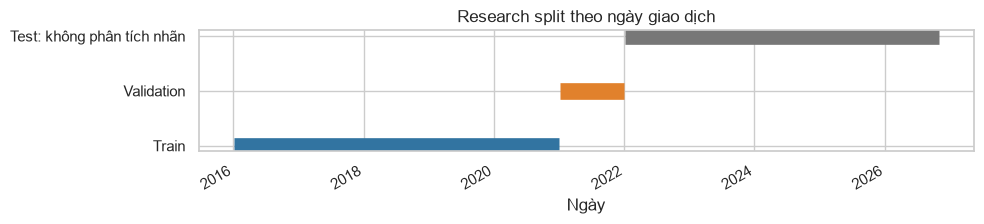

In [2]:
start_year=df.index.min().year
val_start=pd.Timestamp(start_year+cfg['validation']['initial_train_years'],1,1)
test_start=val_start+pd.DateOffset(months=cfg['validation']['val_months'])
train=df.loc[df.index<val_start].copy(); val=df.loc[(df.index>=val_start)&(df.index<test_start)].copy()
# Chỉ lấy index của test để xác định biên; không đọc target test.
test_index=df.index[df.index>=test_start]
assert len(train)>0 and len(val)>0 and len(test_index)>0
actual_val=val.index[0]; actual_test=test_index[0]
positions=pd.Series(df.index,index=df.index)
end1=positions.shift(-1); end4=positions.shift(-(1+cfg['labeling']['fixed_holding_sessions']))
complete=df[names].notna().all(axis=1)
def eligible(part,boundary,end,label):
    idx=part.index; ends=end.loc[idx]; keep=(ends<boundary)&part[label].notna()&complete.loc[idx]
    assert (ends.loc[keep]<boundary).all()
    return part.loc[keep].copy()
tr1=eligible(train,actual_val,end1,'target_direction'); va1=eligible(val,actual_test,end1,'target_direction')
tr2=eligible(train,actual_val,end4,'target_fixed_hold_net_proxy'); va2=eligible(val,actual_test,end4,'target_fixed_hold_net_proxy')
# Chỉ kiểm tra Inf và class cho các khoảng được phép.
for part in (tr1,va1,tr2,va2):
    assert not np.isinf(part[labels].select_dtypes(include='number').to_numpy(dtype=float,na_value=np.nan)).any()
    for c in [x for x in labels if x.startswith('target_')]: assert part[c].dropna().isin([0,1]).all()
period_rows=[]
for label,part,boundary,a,b in [('Train',train,actual_val,tr1,tr2),('Validation',val,actual_test,va1,va2)]:
    period_rows.append([label,str(part.index.min().date()),str(part.index.max().date()),len(part),int(complete.loc[part.index].sum()),len(a),len(b),int((end1.loc[part.index]>=boundary).sum()),int((end4.loc[part.index]>=boundary).sum())])
period_rows.append(['Reserved test',str(test_index.min().date()),str(test_index.max().date()),len(test_index),'không đánh giá','kín','kín','—','—'])
split=pd.DataFrame(period_rows,columns=['Giai đoạn','Đầu','Cuối','Rows','Đủ feature','RQ1 eligible','RQ2 eligible','Purge RQ1','Purge RQ2']); display(split)
fig,ax=plt.subplots(figsize=(10,2.4));
for y,(name,idx,color) in enumerate([('Train',train.index,'#3274a1'),('Validation',val.index,'#e1812c'),('Test: không phân tích nhãn',test_index,'#777777')]):
    ax.plot([idx.min(),idx.max()],[y,y],lw=12,color=color,solid_capstyle='butt',label=name)
ax.set_yticks(range(3),['Train','Validation','Test: không phân tích nhãn']); ax.set_title('Research split theo ngày giao dịch'); ax.set_xlabel('Ngày'); fig.autofmt_xdate(); fig.tight_layout(); fig.savefig(figdir/'02_research_timeline.png',dpi=150); plt.show()
research_notes['split']=f"Train {train.index.min().date()}–{train.index.max().date()} có {len(train)} phiên; validation {val.index.min().date()}–{val.index.max().date()} có {len(val)}; test không phân tích nhãn {test_index.min().date()}–{test_index.max().date()} có {len(test_index)}. Sau warm-up và purge, RQ1 còn {len(tr1)}/{len(va1)} và RQ2 {len(tr2)}/{len(va2)} hàng train/validation. Số bị purge theo ranh giới lần lượt RQ1 {period_rows[0][7]}/{period_rows[1][7]}, RQ2 {period_rows[0][8]}/{period_rows[1][8]}. Không random shuffle; tính theo phiên thực, không phải ngày lịch."

**Diễn giải từ kết quả:** Train 2016-01-04–2020-12-31 có 1251 phiên; validation 2021-01-04–2021-12-31 có 250; test không phân tích nhãn 2022-01-04–2026-10-30 có 1201. Sau warm-up và purge, RQ1 còn 1051/249 và RQ2 1048/246 hàng train/validation. Số bị purge theo ranh giới lần lượt RQ1 1/1, RQ2 4/4. Không random shuffle; tính theo phiên thực, không phải ngày lịch.

## 3. Missing, ổn định số và dữ liệu volume

Phân tích feature trên train và validation để phân biệt warm-up với tỷ số không xác định; không fillna hay thay master. Missing sau lần hợp lệ đầu có thể là trường hợp số học hoặc dữ liệu cần điều tra. Thống kê cực trị có thể làm méo tương quan và mô hình tuyến tính.

,missing,missing_pct,first_valid,missing_after_first
sma_ratio_200,199,13.257828,2016-10-20,0
volatility_63,63,4.197202,2016-04-07,0
sma_ratio_50,49,3.264490,2016-03-18,0
macd_ratio,25,1.665556,2016-02-15,0
ema_ratio_26,25,1.665556,2016-02-15,0
return_lag_21,22,1.465690,2016-02-03,0
momentum_21,21,1.399067,2016-02-02,0
volatility_21,21,1.399067,2016-02-02,0
sma_ratio_20,19,1.265823,2016-01-29,0
bollinger_percent_b_20,19,1.265823,2016-01-29,0


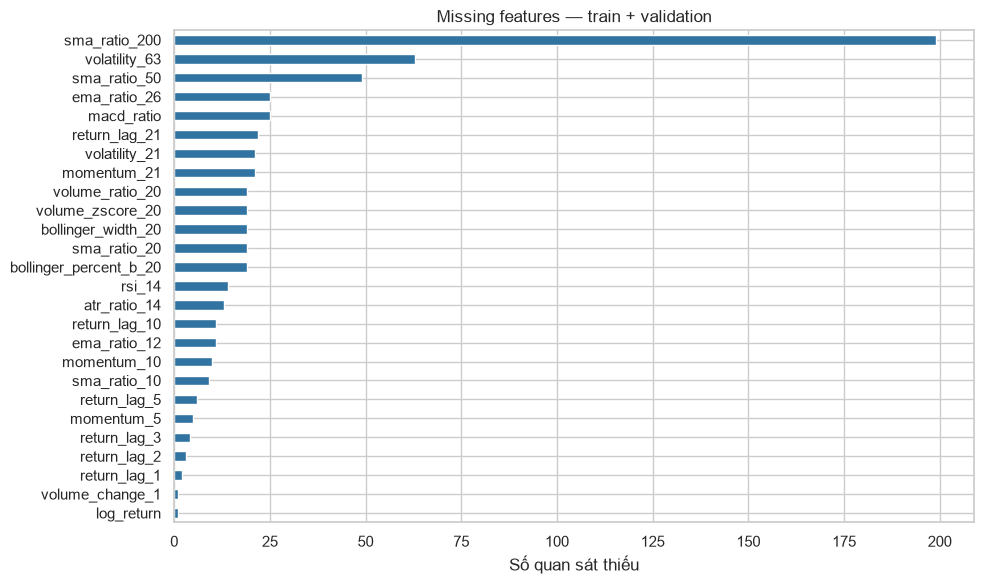

,volume,volume_change_1,volume_zscore_20,volume_ratio_20
date,,,,
2021-10-04,45357500,0.488190,2.215073,1.672896
2021-10-05,26571500,-0.414176,-0.037644,0.988545


In [3]:
research=pd.concat([train[names],val[names]])
missing=pd.DataFrame({'missing':research.isna().sum(),'missing_pct':100*research.isna().mean(),'first_valid':research.apply(lambda x: x.first_valid_index()),'missing_after_first':research.apply(lambda x: x.loc[x.first_valid_index():].isna().sum() if x.first_valid_index() is not None else x.isna().sum())}).sort_values('missing',ascending=False)
display(missing)
fig,ax=plt.subplots(figsize=(10,6)); missing['missing'].sort_values().plot.barh(ax=ax,color='#3274a1'); ax.set(xlabel='Số quan sát thiếu',title='Missing features — train + validation'); fig.tight_layout(); fig.savefig(figdir/'02_feature_missing_values.png',dpi=150); plt.show()
anomaly=val.loc['2021-10-04':'2021-10-05',['volume','volume_change_1','volume_zscore_20','volume_ratio_20']]; display(anomaly)
topmiss=missing.index[0]; post=int(missing.missing_after_first.sum()); d0=val.loc[pd.Timestamp('2021-10-04'),'volume']; d1=val.loc[pd.Timestamp('2021-10-05'),'volume']; change=val.loc[pd.Timestamp('2021-10-05'),'volume_change_1']
research_notes['quality'] = f"Trong train+validation, {topmiss} thiếu nhiều nhất: {missing.loc[topmiss,'missing']} hàng ({missing.loc[topmiss,'missing_pct']:.2f}%), chủ yếu do warm-up; tổng missing sau lần hợp lệ đầu là {post}. Hai phiên 04–05/10/2021 có volume {d0:,.0f} và {d1:,.0f}, thay đổi {change:+.2f}; đây là các quan sát trong dataset Research, không tự kết luận lỗi. Giá adjusted và volume cần đối chiếu nguồn và corporate actions. Logistic Regression nhạy scale và cực trị; các phép biến đổi cần được fit trên train."


**Diễn giải từ kết quả:** Trong train+validation, sma_ratio_200 thiếu nhiều nhất: 199 hàng (13.26%), chủ yếu do warm-up; tổng missing sau lần hợp lệ đầu là 0. Hai phiên 04–05/10/2021 có volume 45,357,500 và 26,571,500, thay đổi -0.41; đây là các quan sát trong dataset Research, không tự kết luận lỗi. Giá adjusted và volume cần đối chiếu nguồn và corporate actions. Logistic Regression nhạy scale và cực trị; các phép biến đổi cần được fit trên train.

## 4. Phân phối 26 feature

Dùng train để phát triển giả thuyết. Histogram và boxplot hiển thị khoảng 1%–99% chỉ để nhìn rõ phần trung tâm; bảng vẫn dùng dữ liệu đầy đủ và hiển thị min/max, skewness, kurtosis dư. Không cắt hoặc sửa observations trong phép tính. Độ lệch và đuôi dài chỉ là mô tả, không phải kiểm định phân phối.

,count,mean,std,min,1%,25%,50%,75%,99%,max,skew,kurtosis_excess,missing_pct
log_return,1250.0,0.00145,0.01999,-0.07236,-0.05328,-0.00892,0.00000,0.01197,0.05330,0.06700,-0.06668,1.38635,0.07994
return_lag_1,1249.0,0.00144,0.02000,-0.07236,-0.05330,-0.00892,0.00000,0.01196,0.05331,0.06700,-0.06540,1.38518,0.15987
return_lag_2,1248.0,0.00145,0.02000,-0.07236,-0.05331,-0.00891,0.00000,0.01196,0.05331,0.06700,-0.06703,1.38714,0.23981
return_lag_3,1247.0,0.00145,0.02001,-0.07236,-0.05333,-0.00891,0.00000,0.01197,0.05332,0.06700,-0.06702,1.38363,0.31974
return_lag_5,1245.0,0.00142,0.02001,-0.07236,-0.05336,-0.00892,0.00000,0.01172,0.05333,0.06700,-0.06393,1.38672,0.47962
return_lag_10,1240.0,0.00138,0.02003,-0.07236,-0.05344,-0.00900,0.00000,0.01156,0.05336,0.06700,-0.05998,1.38603,0.87930
return_lag_21,1229.0,0.00134,0.02000,-0.07236,-0.05362,-0.00900,0.00000,0.01155,0.05343,0.06700,-0.06307,1.41659,1.75859
sma_ratio_10,1242.0,0.00691,0.03434,-0.10961,-0.08154,-0.01383,0.00701,0.02695,0.09270,0.15265,-0.00837,0.97613,0.71942
sma_ratio_20,1232.0,0.01504,0.05242,-0.17752,-0.11902,-0.01693,0.01503,0.04697,0.15105,0.24891,0.05358,1.01139,1.51878
sma_ratio_50,1202.0,0.03821,0.09449,-0.27622,-0.18540,-0.01952,0.03644,0.09540,0.28716,0.42622,0.21836,0.84999,3.91687


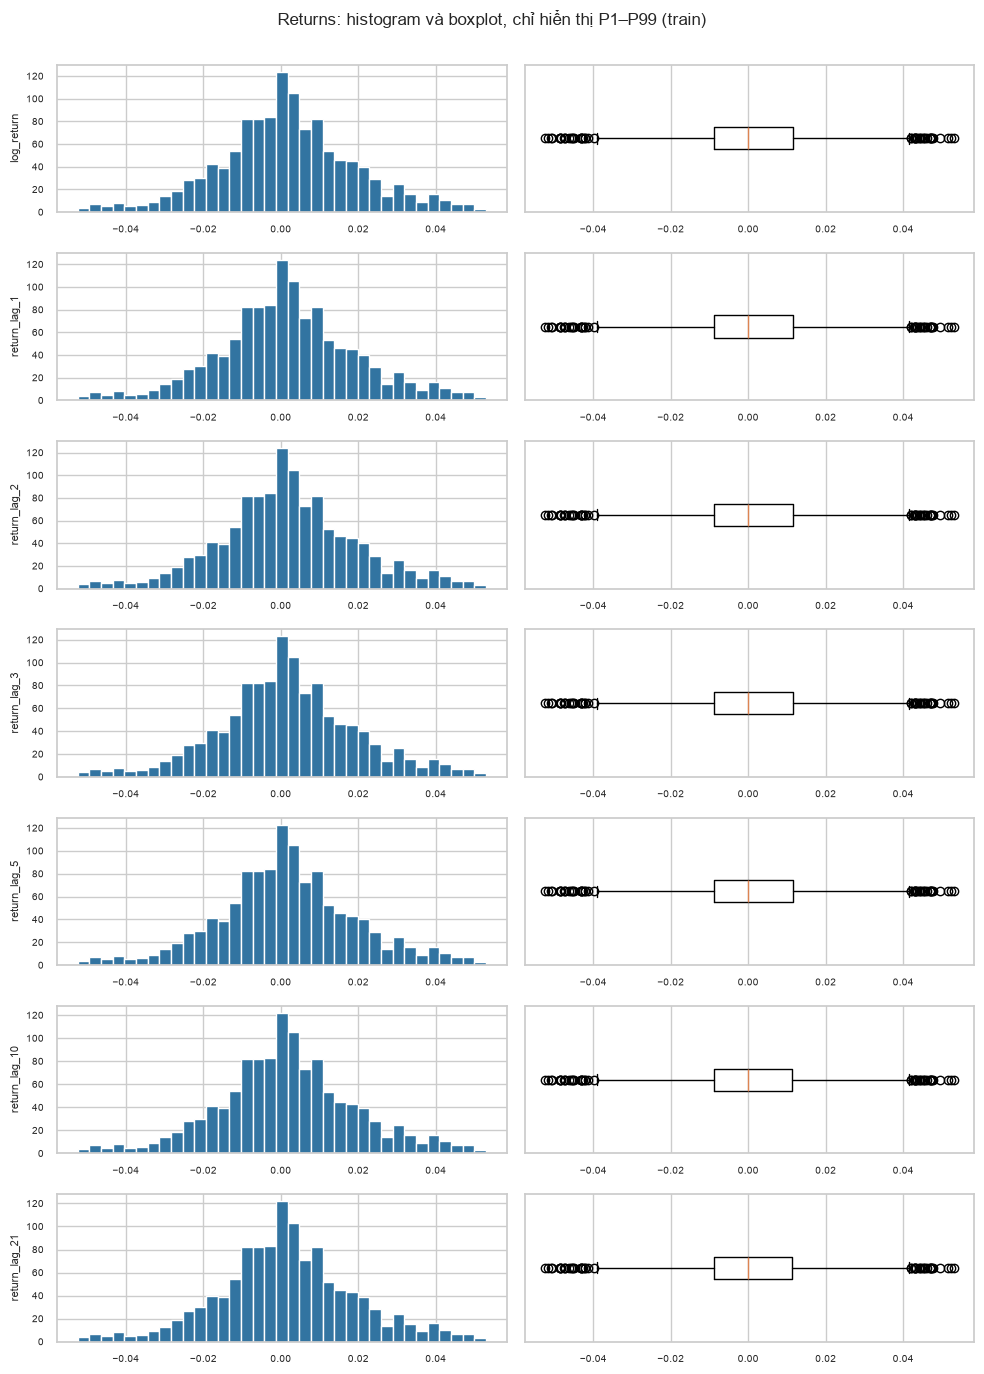

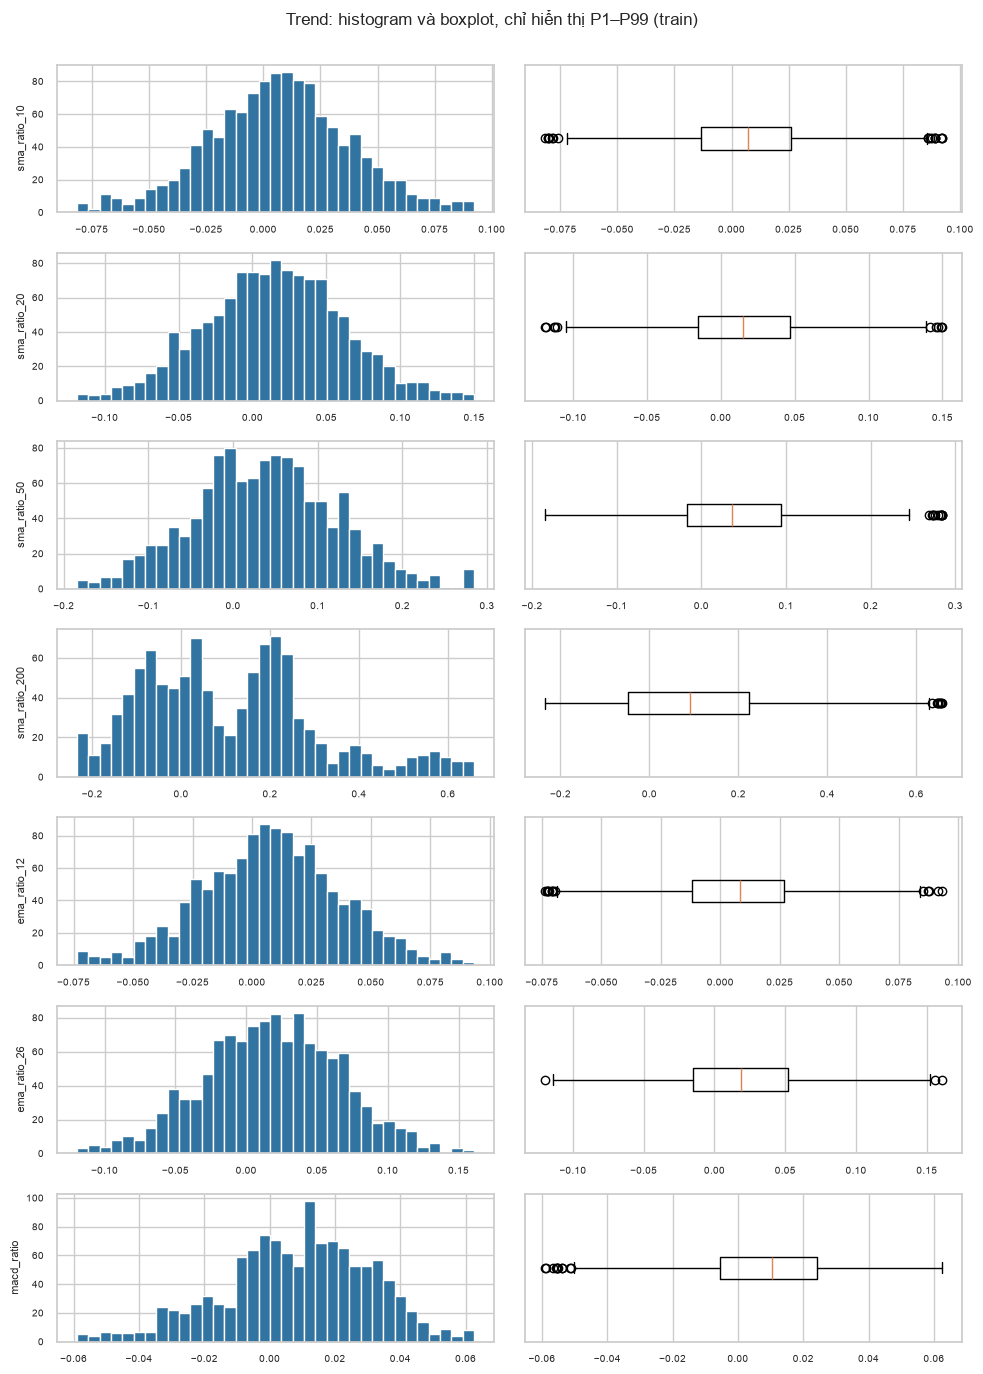

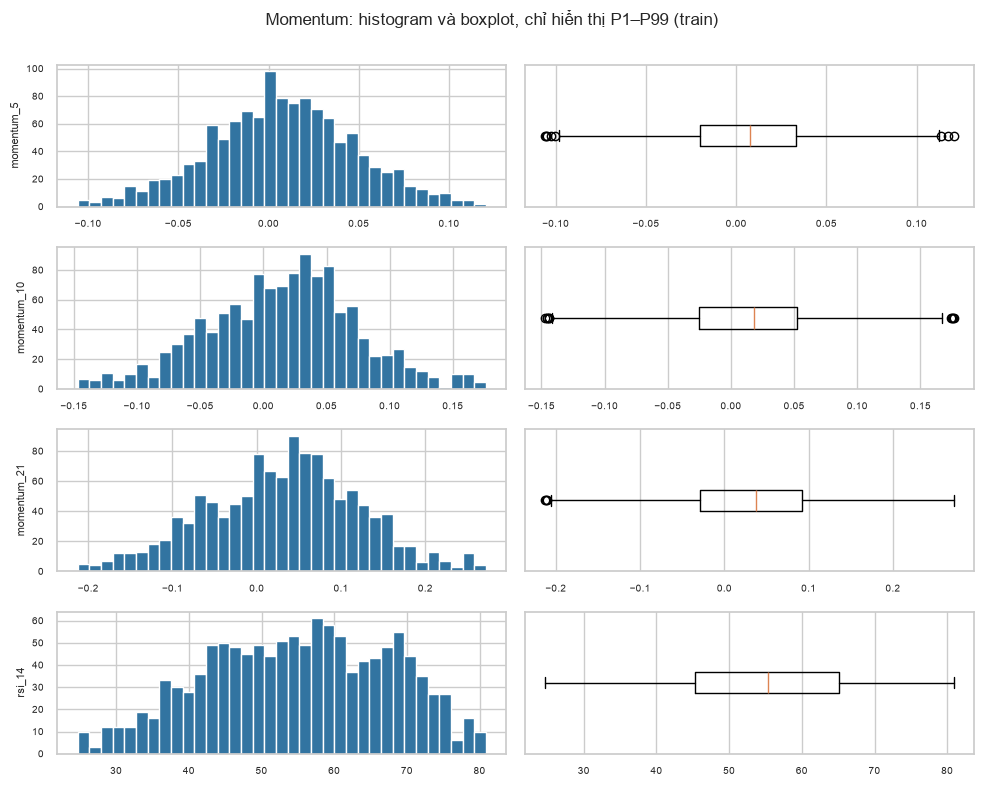

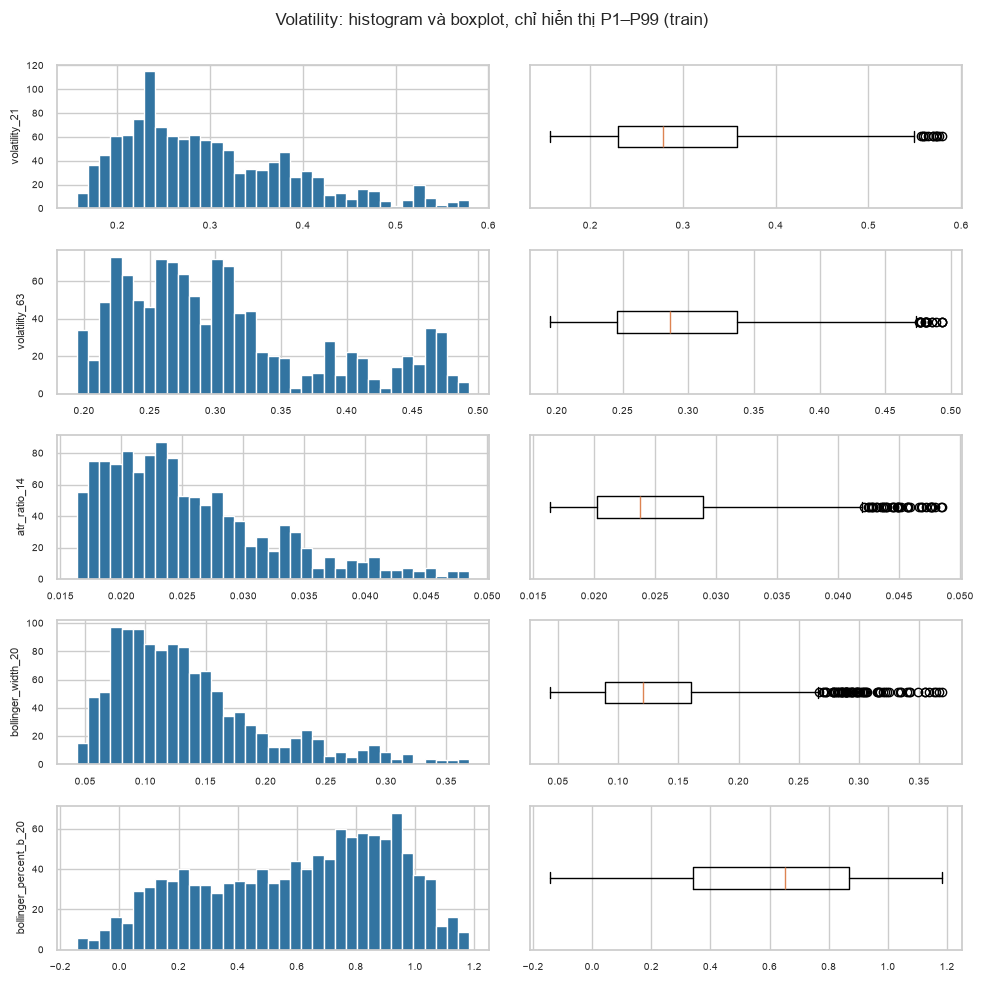

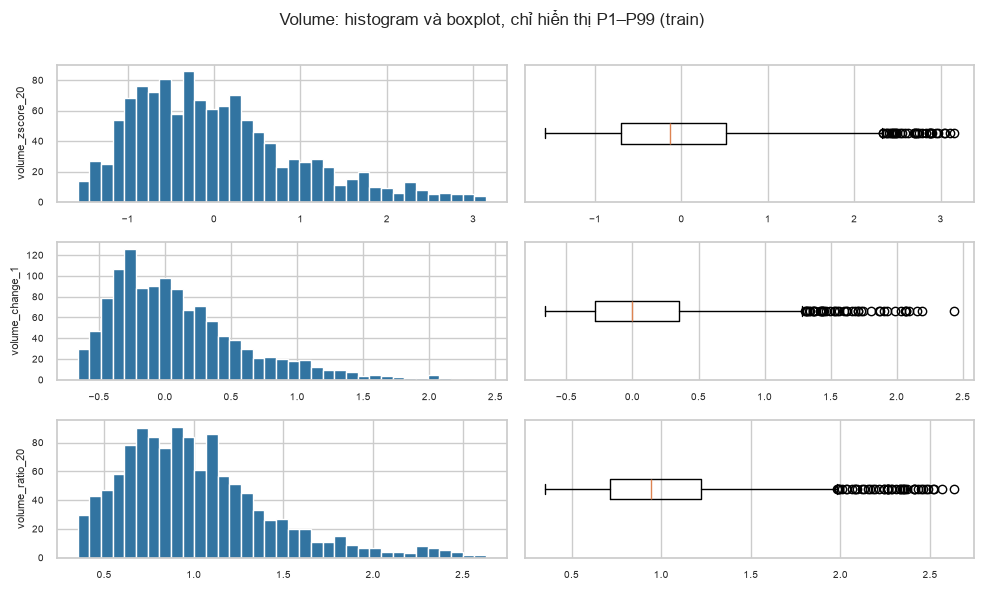

In [4]:
groups={'Returns':[x for x in names if x=='log_return' or x.startswith('return_lag_')], 'Trend':[x for x in names if x.startswith(('sma_ratio_','ema_ratio_')) or x=='macd_ratio'], 'Momentum':[x for x in names if x.startswith(('momentum_','rsi_'))], 'Volatility':[x for x in names if x.startswith(('volatility_','atr_ratio_','bollinger_'))], 'Volume':[x for x in names if x.startswith('volume_')]}
assert sum(map(len,groups.values()))==len(names) and set(sum(groups.values(),[]))==set(names)
category={f:g for g,fs in groups.items() for f in fs}
stats=train[names].describe(percentiles=[.01,.25,.5,.75,.99]).T
stats['skew']=train[names].skew(); stats['kurtosis_excess']=train[names].kurt(); stats['missing_pct']=100*train[names].isna().mean()
display(stats.round(5))
for group,fs in groups.items():
    fig,axes=plt.subplots(len(fs),2,figsize=(10,2.0*len(fs)),squeeze=False)
    for i,f in enumerate(fs):
        x=train[f].dropna(); lo,hi=x.quantile([.01,.99]); shown=x[(x>=lo)&(x<=hi)]
        axes[i,0].hist(shown,bins=35,color='#3274a1'); axes[i,0].set_ylabel(f,fontsize=8); axes[i,0].tick_params(labelsize=7)
        axes[i,1].boxplot(shown,orientation="horizontal",showfliers=True); axes[i,1].set_yticks([]); axes[i,1].tick_params(labelsize=7)
    fig.suptitle(f'{group}: histogram và boxplot, chỉ hiển thị P1–P99 (train)',fontsize=12); fig.tight_layout(rect=[0,0,1,.98]); fig.savefig(figdir/f'02_feature_distributions_{group.lower()}.png',dpi=150); plt.show()
log=train['log_return'].dropna(); rsi=train['rsi_14'].dropna(); v=train['volume_change_1'].dropna()
research_notes['distribution']=(f"Returns: log_return median {log.median():.5f}, P1/P99 {log.quantile(.01):.4f}/{log.quantile(.99):.4f}, skew {log.skew():.2f}, excess kurtosis {log.kurt():.2f}; đuôi và bất đối xứng là mô tả mẫu. Trend: sma_ratio_20 median {train.sma_ratio_20.median():.4f}, min/max {train.sma_ratio_20.min():.3f}/{train.sma_ratio_20.max():.3f}; horizon dài có thể phản ứng chậm hơn. Momentum: RSI median {rsi.median():.1f}, P25–P75 {rsi.quantile(.25):.1f}–{rsi.quantile(.75):.1f}; std momentum_5/21 = {train.momentum_5.std():.3f}/{train.momentum_21.std():.3f}. Volatility: volatility_21 median/max {train.volatility_21.median():.3f}/{train.volatility_21.max():.3f}, đỉnh ngày {train.volatility_21.idxmax().date()}; volatility_63 median/max {train.volatility_63.median():.3f}/{train.volatility_63.max():.3f}. Volume: volume_change_1 max {v.max():.3f}, P99 {v.quantile(.99):.3f}; volume_zscore_20 max {train.volume_zscore_20.max():.3f}. Biểu đồ cắt phạm vi hiển thị, không có nghĩa các cực trị đã bị loại khỏi thống kê.")

**Diễn giải từ kết quả:** Returns: log_return median 0.00000, P1/P99 -0.0533/0.0533, skew -0.07, excess kurtosis 1.39; đuôi và bất đối xứng là mô tả mẫu. Trend: sma_ratio_20 median 0.0150, min/max -0.178/0.249; horizon dài có thể phản ứng chậm hơn. Momentum: RSI median 55.4, P25–P75 45.0–65.4; std momentum_5/21 = 0.045/0.100. Volatility: volatility_21 median/max 0.278/0.639, đỉnh ngày 2020-04-07; volatility_63 median/max 0.286/0.503. Volume: volume_change_1 max 5.627, P99 2.436; volume_zscore_20 max 3.995. Biểu đồ cắt phạm vi hiển thị, không có nghĩa các cực trị đã bị loại khỏi thống kê.

## 5. Pearson và Spearman giữa các features

Hai ma trận dùng pairwise-complete train, Pearson cho tuyến tính và Spearman cho quan hệ đơn điệu theo thứ hạng. Ngưỡng |r| ≥ 0,90 chỉ là cảnh báo redundancy, không phải quy tắc loại feature. Mẫu khác nhau giữa cặp nếu thiếu; các cửa sổ giá có lịch sử chồng lấn.

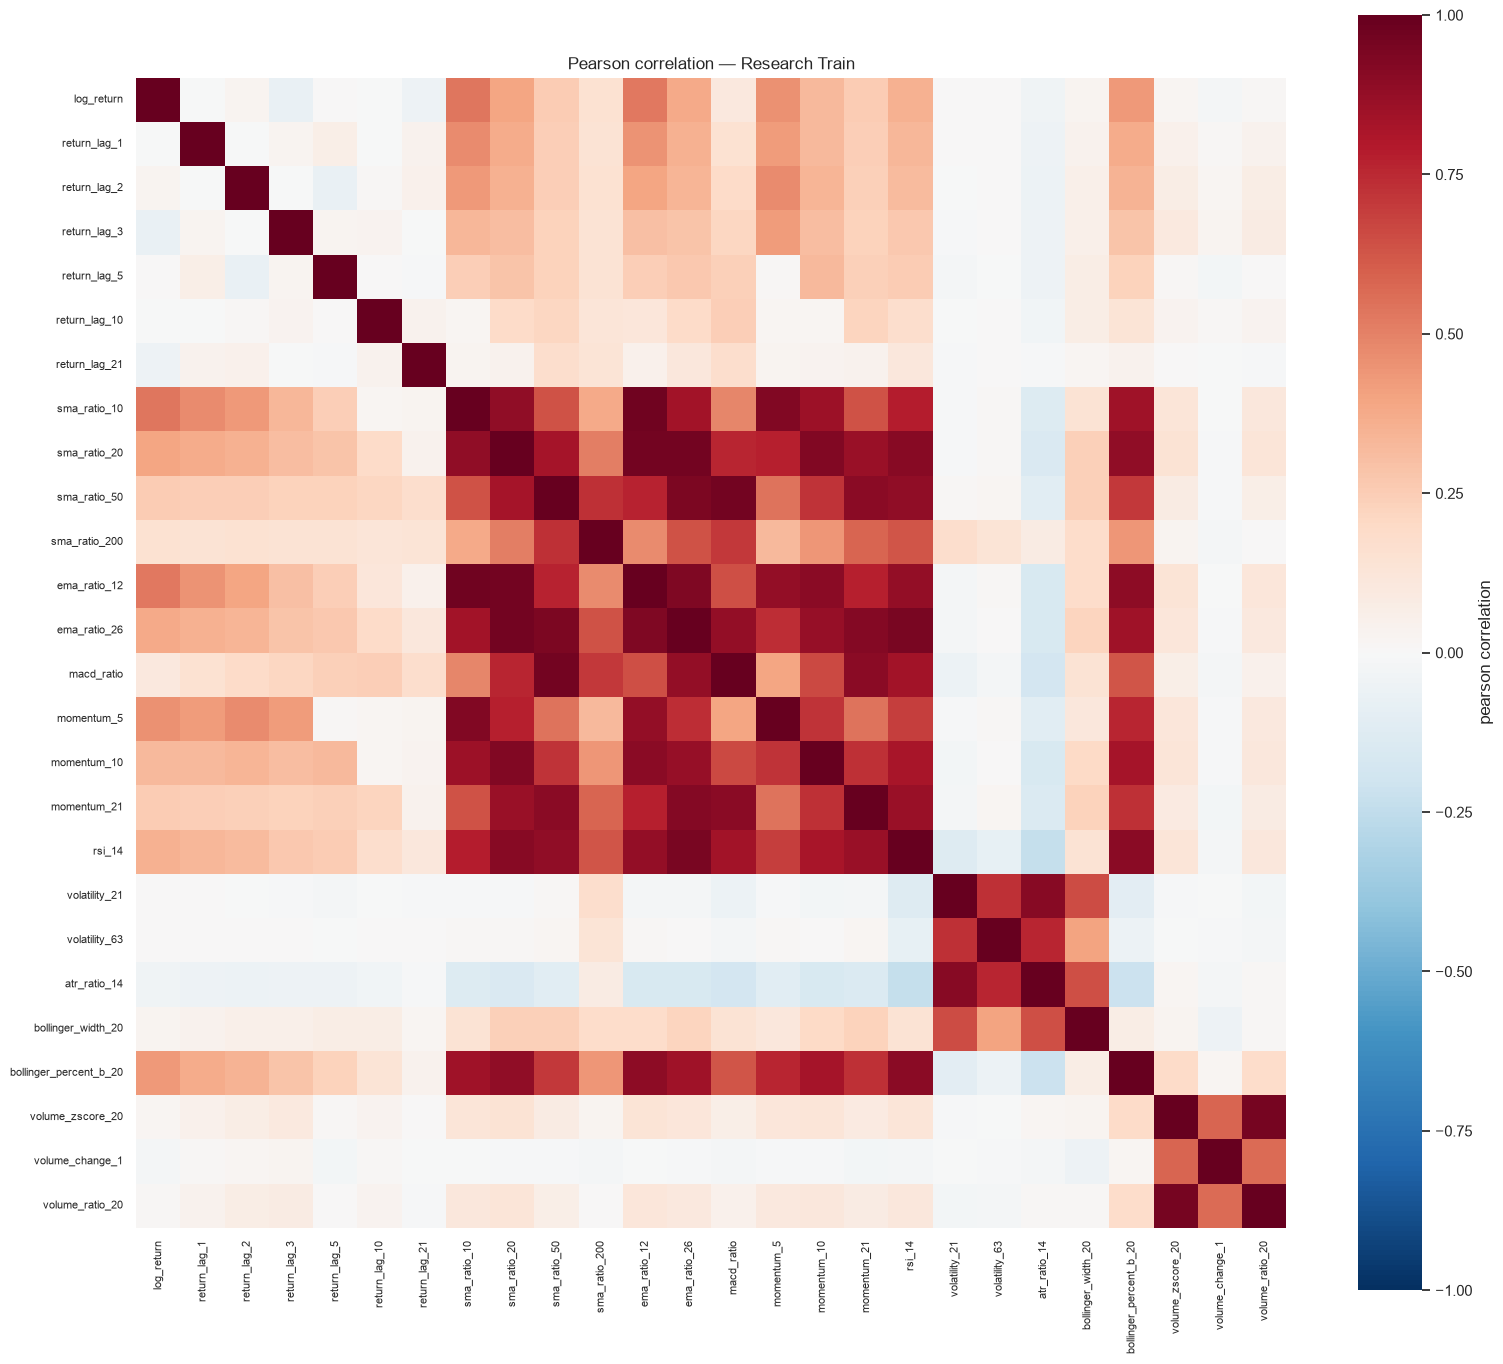

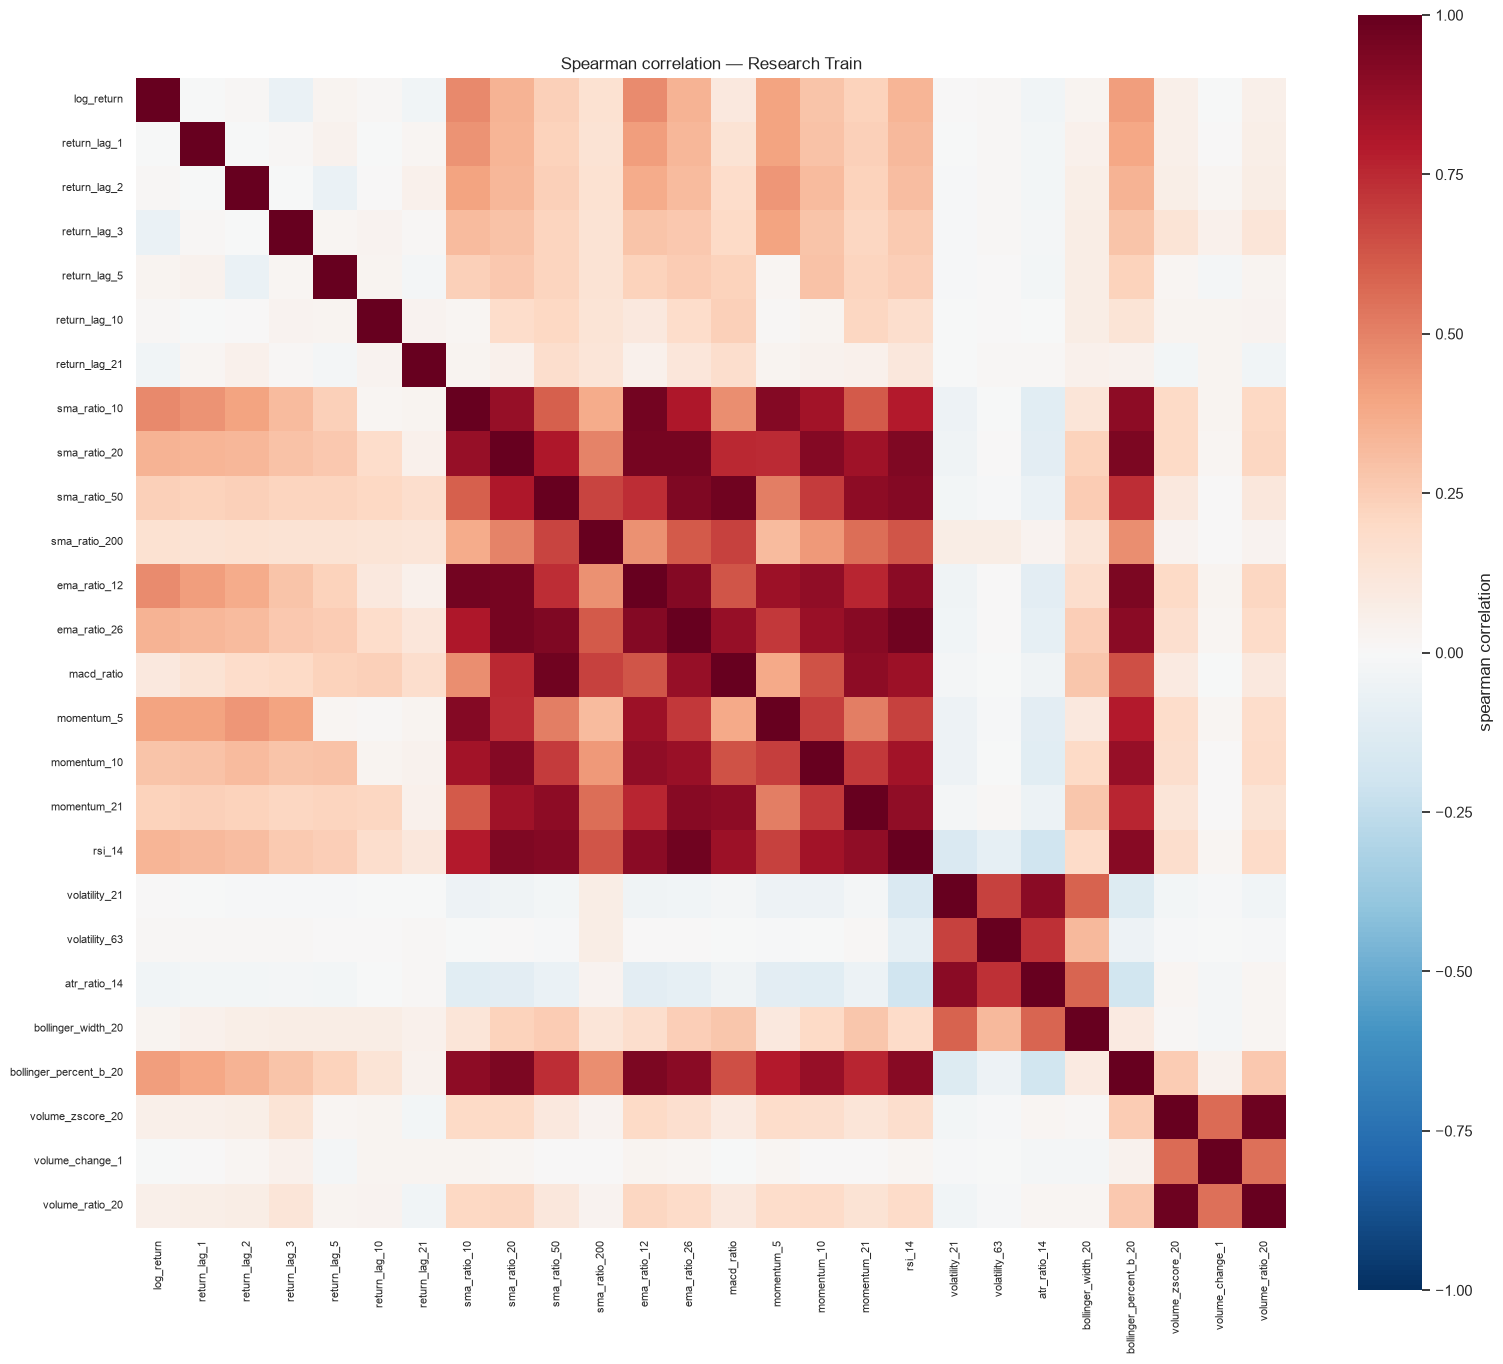

,A,B,Pearson,Spearman,Nhận xét
0,sma_ratio_10,ema_ratio_12,0.969515,0.961892,Có thể trùng thông tin; cần kiểm tra bổ sung
3,sma_ratio_20,ema_ratio_26,0.964903,0.959806,Có thể trùng thông tin; cần kiểm tra bổ sung
2,sma_ratio_20,ema_ratio_12,0.961830,0.957351,Có thể trùng thông tin; cần kiểm tra bổ sung
8,sma_ratio_50,macd_ratio,0.961208,0.970733,Có thể trùng thông tin; cần kiểm tra bổ sung
18,volume_zscore_20,volume_ratio_20,0.953507,0.983941,Có thể trùng thông tin; cần kiểm tra bổ sung
14,ema_ratio_26,rsi_14,0.948237,0.975871,Có thể trùng thông tin; cần kiểm tra bổ sung
7,sma_ratio_50,ema_ratio_26,0.940265,0.930907,Có thể trùng thông tin; cần kiểm tra bổ sung
11,ema_ratio_12,ema_ratio_26,0.932429,0.920768,Có thể trùng thông tin; cần kiểm tra bổ sung
4,sma_ratio_20,momentum_10,0.928186,0.919930,Có thể trùng thông tin; cần kiểm tra bổ sung
1,sma_ratio_10,momentum_5,0.927835,0.915601,Có thể trùng thông tin; cần kiểm tra bổ sung


In [5]:
pear=train[names].corr(method='pearson'); spear=train[names].corr(method='spearman')
for method,mat in [('pearson',pear),('spearman',spear)]:
    fig,ax=plt.subplots(figsize=(16,14)); sns.heatmap(mat,vmin=-1,vmax=1,center=0,cmap='RdBu_r',square=True,ax=ax,cbar_kws={'label':method+' correlation'}); ax.set_title(method.title()+' correlation — Research Train'); ax.tick_params(axis='x',labelrotation=90,labelsize=8); ax.tick_params(axis='y',labelsize=8); fig.tight_layout(); fig.savefig(figdir/f'02_feature_{method}_correlation.png',dpi=160,bbox_inches='tight'); plt.show()
pairs=[]
for i,a in enumerate(names):
    for b in names[i+1:]:
        if max(abs(pear.loc[a,b]),abs(spear.loc[a,b]))>=.9: pairs.append((a,b,pear.loc[a,b],spear.loc[a,b],'Có thể trùng thông tin; cần kiểm tra bổ sung'))
pairs=pd.DataFrame(pairs,columns=['A','B','Pearson','Spearman','Nhận xét']).sort_values('Pearson',key=abs,ascending=False); display(pairs)
first=pairs.iloc[0] if len(pairs) else None
research_notes['correlation']=f"Có {len(pairs)} cặp đạt |Pearson| hoặc |Spearman| ≥ 0,90 trên train. " + (f"Cặp đầu theo |Pearson|: {first['A']}–{first['B']}, Pearson {first['Pearson']:.3f}, Spearman {first['Spearman']:.3f}. " if first is not None else '') + f"volatility_21–volatility_63: Pearson {pear.loc['volatility_21','volatility_63']:.3f}, Spearman {spear.loc['volatility_21','volatility_63']:.3f}. SMA/EMA và momentum dùng lịch sử giá chồng lấn nên dễ đồng biến. Tương quan không phải predictive power; đa cộng tuyến có thể làm hệ số Logistic Regression thiếu ổn định, còn cây thường phân chia tầm quan trọng giữa biến tương tự. Không loại feature ở đây."

**Diễn giải từ kết quả:** Có 19 cặp đạt |Pearson| hoặc |Spearman| ≥ 0,90 trên train. Cặp đầu theo |Pearson|: sma_ratio_10–ema_ratio_12, Pearson 0.970, Spearman 0.962. volatility_21–volatility_63: Pearson 0.730, Spearman 0.687. SMA/EMA và momentum dùng lịch sử giá chồng lấn nên dễ đồng biến. Tương quan không phải predictive power; đa cộng tuyến có thể làm hệ số Logistic Regression thiếu ổn định, còn cây thường phân chia tầm quan trọng giữa biến tương tự. Không loại feature ở đây.

## 6. Phân phối nhãn được phép

Dùng các hàng đủ tất cả 26 feature và nhãn đã purge riêng cho từng mục tiêu. Tỷ lệ lớp đa số là baseline mô tả; baseline thực sự ngoài mẫu phải được xác định từ train. Net proxy chỉ là phép tính giả định, không phải realized PnL.

In [6]:
class_rows=[]
for period,rq,part,col in [('Train','RQ1',tr1,'target_direction'),('Validation','RQ1',va1,'target_direction'),('Train','RQ2',tr2,'target_fixed_hold_net_proxy'),('Validation','RQ2',va2,'target_fixed_hold_net_proxy')]:
    v=part[col].astype(int); n=len(v); n1=int(v.sum()); class_rows.append([period,rq,n,n1,n-n1,100*n1/n,100*(n-n1)/n,100*max(n1,n-n1)/n])
classes=pd.DataFrame(class_rows,columns=['period','target','n','positive','negative','positive_pct','negative_pct','majority_pct']); display(classes.round(2))
proxy_stats=pd.concat({'Train':tr2[['forward_trade_gross_return','forward_trade_net_return_proxy']].describe(percentiles=[.1,.5,.9]),'Validation':va2[['forward_trade_gross_return','forward_trade_net_return_proxy']].describe(percentiles=[.1,.5,.9])}); display(proxy_stats)
research_notes['labels']=f"Tỷ lệ tăng RQ1 train/validation: {class_rows[0][5]:.2f}%/{class_rows[1][5]:.2f}%; tỷ lệ dương RQ2: {class_rows[2][5]:.2f}%/{class_rows[3][5]:.2f}%. Baseline lớp đa số trong từng mẫu RQ1 là {class_rows[0][7]:.2f}%/{class_rows[1][7]:.2f}%; không dùng lớp đa số validation để fit mô hình. Hai nhãn đo các khoảng giá khác nhau, nên accuracy cần so với baseline và không suy ra lợi nhuận chiến lược."

,period,target,n,positive,negative,positive_pct,negative_pct,majority_pct
0,Train,RQ1,1051,519,532,49.38,50.62,50.62
1,Validation,RQ1,249,131,118,52.61,47.39,52.61
2,Train,RQ2,1048,507,541,48.38,51.62,51.62
3,Validation,RQ2,246,136,110,55.28,44.72,55.28


forward_trade_gross_return  forward_trade_net_return_proxy
Train      count                 1048.000000                     1048.000000
           mean                     0.004373                       -0.000639
           std                      0.037363                        0.037177
           min                     -0.148008                       -0.152259
           10%                     -0.037774                       -0.042575
           50%                      0.004157                       -0.000853
           90%                      0.047288                        0.042063
           max                      0.215947                        0.209880
Validation count                  246.000000                      246.000000
           mean                     0.005460                        0.000443
           std                      0.037878                        0.037689
           min                     -0.151737                       -0.155969
           10%                     -0.041566                       -0.046348
           50%                      0.008677                        0.003645
           90%                      0.049978                        0.044739
           max                      0.114851                        0.109289

**Diễn giải từ kết quả:** Tỷ lệ tăng RQ1 train/validation: 49.38%/52.61%; tỷ lệ dương RQ2: 48.38%/55.28%. Baseline lớp đa số trong từng mẫu RQ1 là 50.62%/52.61%; không dùng lớp đa số validation để fit mô hình. Hai nhãn đo các khoảng giá khác nhau, nên accuracy cần so với baseline và không suy ra lợi nhuận chiến lược.

## 7. Time-series Information Coefficient

Với mỗi feature trên train, Pearson và Spearman corr(X_t, forward_log_return_1) dùng các cặp hợp lệ trong eligible RQ1; IC ở đây là time-series của một mã, không phải cross-sectional. Xếp hạng theo |train IC|, hoàn tất trước khi xem validation. Không dùng p-value IID hay gán significance vì 26 phép thử và phụ thuộc thời gian.

,group,n,missing,pearson,spearman,abs_ic
feature,,,,,,
return_lag_2,Returns,1051,0,-0.06384,-0.06229,0.06229
volume_ratio_20,Volume,1051,0,0.04721,0.06182,0.06182
volume_change_1,Volume,1051,0,0.04236,0.05750,0.05750
momentum_21,Momentum,1051,0,0.04945,0.05586,0.05586
macd_ratio,Trend,1051,0,0.04383,0.05533,0.05533
volume_zscore_20,Volume,1051,0,0.04351,0.05280,0.05280
rsi_14,Momentum,1051,0,0.04974,0.04919,0.04919
sma_ratio_200,Trend,1051,0,0.03993,0.04883,0.04883
ema_ratio_26,Trend,1051,0,0.04163,0.04849,0.04849


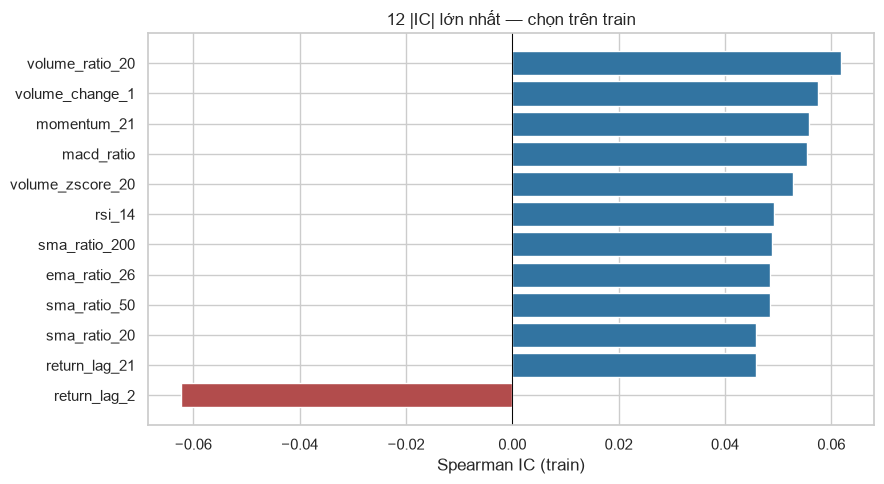

In [7]:
def association(part,col,features=names):
    rows=[]
    for f in features:
        xy=part[[f,col]].dropna(); rows.append([f,category[f],len(xy),part[[f,col]].isna().any(axis=1).sum(),xy[f].corr(xy[col],method='pearson'),xy[f].corr(xy[col],method='spearman')])
    return pd.DataFrame(rows,columns=['feature','group','n','missing','pearson','spearman']).set_index('feature')
ic=association(tr1,'forward_log_return_1'); ic['abs_ic']=ic.spearman.abs(); ic=ic.sort_values('abs_ic',ascending=False); selected=list(ic.index[:5]); display(ic.round(5))
fig,ax=plt.subplots(figsize=(9,5)); top=ic.head(12).sort_values('spearman'); ax.barh(top.index,top.spearman,color=['#b24c4c' if x<0 else '#3274a1' for x in top.spearman]); ax.axvline(0,color='black',lw=.7); ax.set(xlabel='Spearman IC (train)',title='12 |IC| lớn nhất — chọn trên train'); fig.tight_layout(); fig.savefig(figdir/'02_feature_target_ic.png',dpi=150); plt.show()
research_notes['ic']=f"Ba |IC| lớn nhất trên train: "+'; '.join(f'{f} {ic.loc[f,"spearman"]:+.4f} (n={int(ic.loc[f,"n"])})' for f in ic.index[:3])+f". Đây là thứ tự mô tả, không phải các feature đã chứng minh dự báo: {len(names)} phép thử, phụ thuộc thời gian và nhiễu chọn mẫu chưa được hiệu chỉnh. Chỉ 5 feature đầu theo train được đóng băng để đối chiếu validation. Không dùng test target."

**Diễn giải từ kết quả:** Ba |IC| lớn nhất trên train: return_lag_2 -0.0623 (n=1051); volume_ratio_20 +0.0618 (n=1051); volume_change_1 +0.0575 (n=1051). Đây là thứ tự mô tả, không phải các feature đã chứng minh dự báo: 26 phép thử, phụ thuộc thời gian và nhiễu chọn mẫu chưa được hiệu chỉnh. Chỉ 5 feature đầu theo train được đóng băng để đối chiếu validation. Không dùng test target.

## 8. Return và tỷ lệ lớp theo quantile

Bộ đại diện được xác định trước theo 5 nhóm: log_return, sma_ratio_20, momentum_5, volatility_21, volume_zscore_20. Chia quantile trên train; qcut bỏ cạnh trùng và báo số bin thực, không giả định số lượng bằng nhau. So sánh mean/median, tỷ lệ tăng và n chỉ để quan sát hình dạng.

,feature,bin,n,x_min,x_max,mean_return,median_return,positive_rate
0,log_return,"(-0.0734, -0.012]",211,-0.07236,-0.01203,0.00285,0.00347,0.55450
1,log_return,"(-0.012, -0.00228]",210,-0.01195,-0.00228,-0.00042,0.00000,0.47619
2,log_return,"(-0.00228, 0.00428]",210,-0.00226,0.00428,-0.00075,0.00000,0.43810
3,log_return,"(0.00428, 0.0157]",210,0.00431,0.01571,0.00270,0.00170,0.51429
4,log_return,"(0.0157, 0.067]",210,0.01593,0.06700,0.00170,0.00000,0.48571
5,sma_ratio_20,"(-0.179, -0.0304]",211,-0.17752,-0.03036,0.00135,0.00000,0.47867
6,sma_ratio_20,"(-0.0304, -0.00206]",210,-0.03035,-0.00206,-0.00106,0.00000,0.43810
7,sma_ratio_20,"(-0.00206, 0.0229]",210,-0.00196,0.02288,0.00030,0.00000,0.49524
8,sma_ratio_20,"(0.0229, 0.0519]",210,0.02300,0.05186,0.00256,0.00144,0.52381
9,sma_ratio_20,"(0.0519, 0.249]",210,0.05210,0.24891,0.00294,0.00208,0.53333


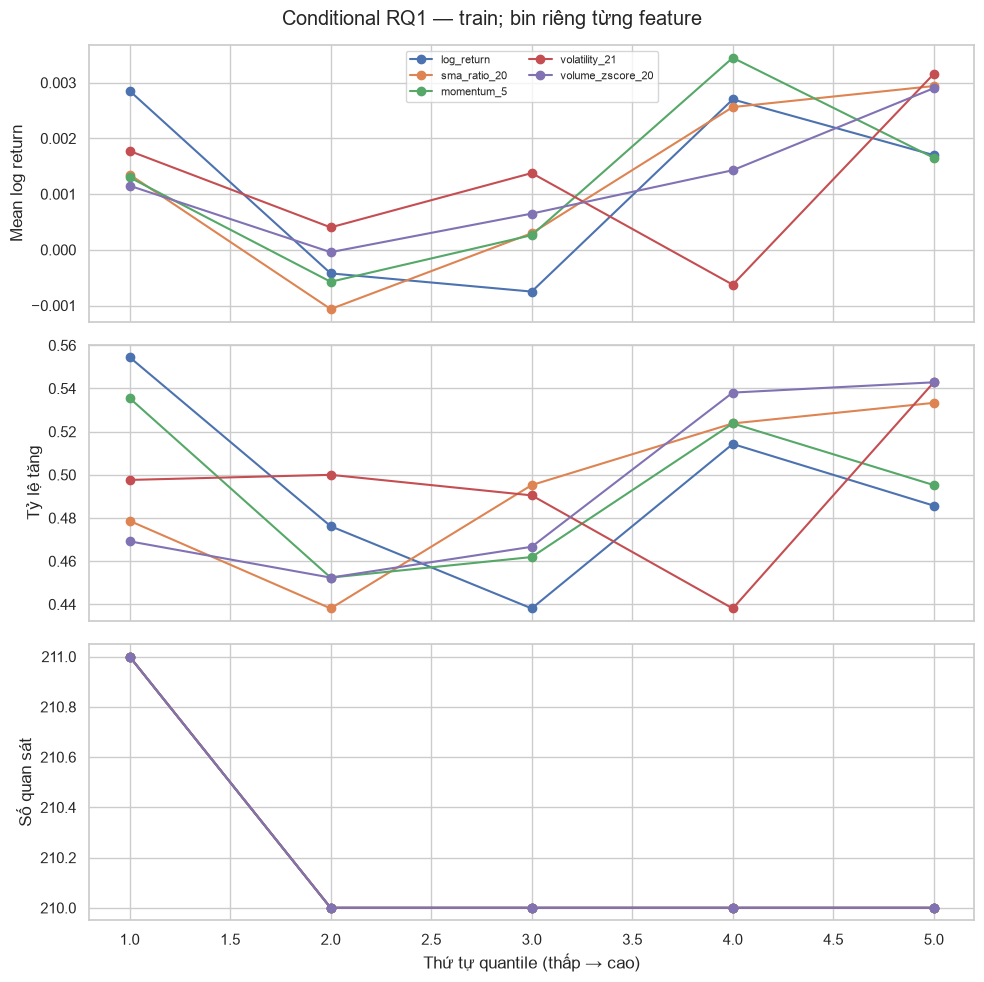

In [8]:
representatives=['log_return','sma_ratio_20','momentum_5','volatility_21','volume_zscore_20']; bins=[]
for f in representatives:
    x=tr1[[f,'forward_log_return_1','target_direction']].dropna().copy()
    try: x['bin']=pd.qcut(x[f],q=5,duplicates='drop')
    except ValueError: continue
    for b,g in x.groupby('bin',observed=True,sort=True):
        bins.append([f,str(b),len(g),g[f].min(),g[f].max(),g.forward_log_return_1.mean(),g.forward_log_return_1.median(),g.target_direction.astype(float).mean()])
conditional=pd.DataFrame(bins,columns=['feature','bin','n','x_min','x_max','mean_return','median_return','positive_rate']); display(conditional.round(5))
fig,axes=plt.subplots(3,1,figsize=(10,10),sharex=True)
for f in representatives:
    z=conditional[conditional.feature==f].reset_index(drop=True); axes[0].plot(range(1,len(z)+1),z.mean_return,marker='o',label=f); axes[1].plot(range(1,len(z)+1),z.positive_rate,marker='o'); axes[2].plot(range(1,len(z)+1),z.n,marker='o')
axes[0].set_ylabel('Mean log return'); axes[1].set_ylabel('Tỷ lệ tăng'); axes[2].set_ylabel('Số quan sát'); axes[2].set_xlabel('Thứ tự quantile (thấp → cao)'); axes[0].legend(fontsize=8,ncol=2); fig.suptitle('Conditional RQ1 — train; bin riêng từng feature'); fig.tight_layout(); fig.savefig(figdir/'02_feature_conditional_returns.png',dpi=150); plt.show()
qnotes=[]
for f in representatives:
    z=conditional[conditional.feature==f]; vals=z.mean_return.to_numpy(); mono=bool(np.all(np.diff(vals)>=0) or np.all(np.diff(vals)<=0)); qnotes.append(f'{f}: Q thấp/cao mean {vals[0]:+.5f}/{vals[-1]:+.5f}, positive {z.positive_rate.iloc[0]:.1%}/{z.positive_rate.iloc[-1]:.1%}, '+('đơn điệu' if mono else 'không đơn điệu'))
research_notes['conditional']='; '.join(qnotes)+'. Đây là khác biệt mô tả của các bin, có thể do nhiễu hoặc outlier; không suy ra quan hệ phi tuyến đã được kiểm chứng hay đặt ngưỡng giao dịch.' 

**Diễn giải từ kết quả:** log_return: Q thấp/cao mean +0.00285/+0.00170, positive 55.5%/48.6%, không đơn điệu; sma_ratio_20: Q thấp/cao mean +0.00135/+0.00294, positive 47.9%/53.3%, không đơn điệu; momentum_5: Q thấp/cao mean +0.00130/+0.00165, positive 53.6%/49.5%, không đơn điệu; volatility_21: Q thấp/cao mean +0.00177/+0.00316, positive 49.8%/54.3%, không đơn điệu; volume_zscore_20: Q thấp/cao mean +0.00115/+0.00290, positive 46.9%/54.3%, không đơn điệu. Đây là khác biệt mô tả của các bin, có thể do nhiễu hoặc outlier; không suy ra quan hệ phi tuyến đã được kiểm chứng hay đặt ngưỡng giao dịch.

## 9. Ổn định theo năm và validation

Các giả thuyết được khóa theo top 5 |IC| train trước khi xem validation. Tính IC theo năm trên train và đối chiếu với validation đã purge. 2016 có warm-up dài nên mẫu ngắn; không dùng p-value IID. Validation đã được quan sát ở đây nên không còn là tập độc lập vô hạn nếu tiếp tục điều chỉnh.

feature,macd_ratio,momentum_21,return_lag_2,volume_change_1,volume_ratio_20
year,,,,,
2016,0.0001,-0.1071,-0.1650,-0.0892,-0.0351
2017,-0.0671,-0.0072,-0.0392,0.0687,0.0192
2018,0.0390,0.0403,-0.0619,0.0925,0.1557
2019,-0.0305,-0.0209,-0.0932,0.0623,0.0585
2020,0.0385,0.0454,-0.0802,0.0226,-0.0189


feature,macd_ratio,momentum_21,return_lag_2,volume_change_1,volume_ratio_20
year,,,,,
2016,52,52,52,52,52
2017,250,250,250,250,250
2018,248,248,248,248,248
2019,250,250,250,250,250
2020,251,251,251,251,251


,train_ic,validation_ic,train_n,validation_n,same_sign,magnitude_change
feature,,,,,,
return_lag_2,-0.06229,-0.00442,1051,249,True,-0.05786
volume_ratio_20,0.06182,0.04750,1051,249,True,-0.01432
volume_change_1,0.05750,-0.01579,1051,249,False,-0.04171
momentum_21,0.05586,0.03198,1051,249,True,-0.02388
macd_ratio,0.05533,0.04351,1051,249,True,-0.01182


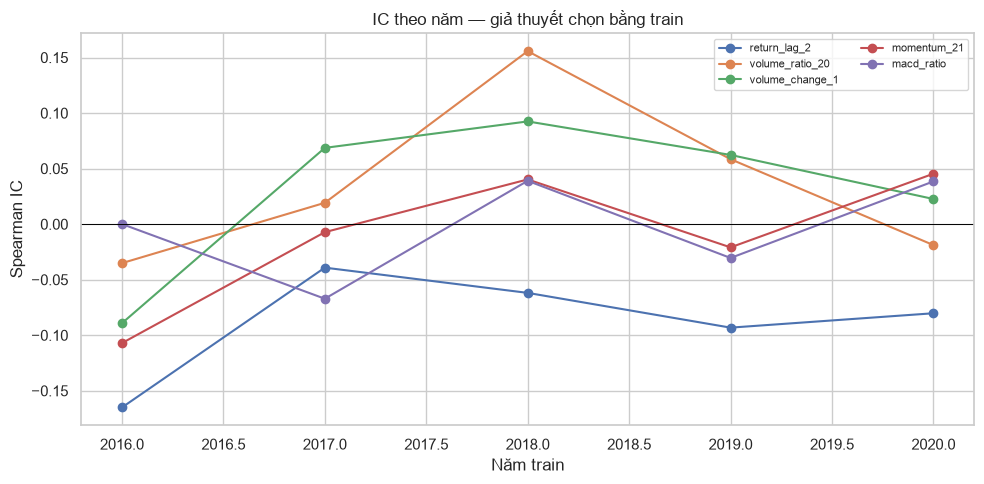

In [9]:
yearly=[]
for year,part in tr1.groupby(tr1.index.year):
    a=association(part,'forward_log_return_1',selected)
    for f in selected: yearly.append([year,f,int(a.loc[f,'n']),a.loc[f,'spearman']])
yearly=pd.DataFrame(yearly,columns=['year','feature','n','ic']); display(yearly.pivot(index='year',columns='feature',values='ic').round(4)); display(yearly.pivot(index='year',columns='feature',values='n'))
vic=association(va1,'forward_log_return_1',selected)
compare=pd.DataFrame({'train_ic':ic.loc[selected,'spearman'],'validation_ic':vic.spearman,'train_n':ic.loc[selected,'n'],'validation_n':vic.n}); compare['same_sign']=np.sign(compare.train_ic)==np.sign(compare.validation_ic); compare['magnitude_change']=compare.validation_ic.abs()-compare.train_ic.abs(); display(compare.round(5))
fig,ax=plt.subplots(figsize=(10,5));
for f in selected:
    a=yearly[yearly.feature==f]; ax.plot(a.year,a.ic,marker='o',label=f)
ax.axhline(0,color='black',lw=.7); ax.set(xlabel='Năm train',ylabel='Spearman IC',title='IC theo năm — giả thuyết chọn bằng train'); ax.legend(fontsize=8,ncol=2); fig.tight_layout(); fig.savefig(figdir/'02_feature_ic_stability.png',dpi=150); plt.show()
notes_stability=[]
for f in selected:
    z=yearly[yearly.feature==f].ic.dropna(); flips=int((np.sign(z.iloc[1:].to_numpy())!=np.sign(z.iloc[:-1].to_numpy())).sum()); notes_stability.append(f'{f}: train {compare.loc[f,"train_ic"]:+.3f}, validation {compare.loc[f,"validation_ic"]:+.3f}, đảo dấu giữa năm {flips} lần')
research_notes['stability']='; '.join(notes_stability)+'. Đổi dấu hoặc một năm chi phối là khả năng phụ thuộc chế độ; một validation năm không chứng minh hiệu quả 2022–2026.' 

**Diễn giải từ kết quả:** return_lag_2: train -0.062, validation -0.004, đảo dấu giữa năm 0 lần; volume_ratio_20: train +0.062, validation +0.047, đảo dấu giữa năm 2 lần; volume_change_1: train +0.058, validation -0.016, đảo dấu giữa năm 1 lần; momentum_21: train +0.056, validation +0.032, đảo dấu giữa năm 3 lần; macd_ratio: train +0.055, validation +0.044, đảo dấu giữa năm 4 lần. Đổi dấu hoặc một năm chi phối là khả năng phụ thuộc chế độ; một validation năm không chứng minh hiệu quả 2022–2026.

## 10. Độ nhạy outlier trên train

Trên bản sao eligible train, loại các cặp có X dưới P1 hoặc trên P99 riêng từng feature; ngưỡng xác định từ train, không ghi lại master. So sánh Pearson và Spearman trước/sau. Đây là sensitivity chứ không phê duyệt winsorization hay fit preprocessing cho Phase 3; việc loại quan sát thay đổi mẫu và không chứng minh nguyên nhân.

In [10]:
sensitivity=[]
for f in ['volume_change_1','volume_zscore_20','volume_ratio_20','log_return','volatility_21']:
    x=tr1[[f,'forward_log_return_1']].dropna(); lo,hi=x[f].quantile([.01,.99]); y=x[x[f].between(lo,hi)]
    sensitivity.append([f,lo,hi,len(x),len(y),x[f].corr(x.forward_log_return_1,method='pearson'),y[f].corr(y.forward_log_return_1,method='pearson'),x[f].corr(x.forward_log_return_1,method='spearman'),y[f].corr(y.forward_log_return_1,method='spearman')])
sens=pd.DataFrame(sensitivity,columns=['feature','p1','p99','n_full','n_trim','pearson_full','pearson_trim','ic_full','ic_trim']).set_index('feature'); sens['delta_ic']=sens.ic_trim-sens.ic_full; display(sens.round(5))
f=sens.delta_ic.abs().idxmax(); research_notes['sensitivity']=f"Trong 5 feature được kiểm tra, |Δ Spearman IC| lớn nhất sau loại hai đuôi train là {f}: {sens.loc[f,'ic_full']:+.4f} → {sens.loc[f,'ic_trim']:+.4f}, n {int(sens.loc[f,'n_full'])} → {int(sens.loc[f,'n_trim'])}. Pearson có thể thay đổi khác Spearman. Kết quả không chứng minh điểm cực đoan là lỗi; cần thử robust preprocessing fit riêng trên train trong Phase 3."

,p1,p99,n_full,n_trim,pearson_full,pearson_trim,ic_full,ic_trim,delta_ic
feature,,,,,,,,,
volume_change_1,-0.65691,2.31100,1051,1029,0.04236,0.04685,0.05750,0.06167,0.00417
volume_zscore_20,-1.57750,3.10328,1051,1029,0.04351,0.04365,0.05280,0.04647,-0.00633
volume_ratio_20,0.35706,2.54425,1051,1029,0.04721,0.03923,0.06182,0.05323,-0.00859
log_return,-0.05516,0.05329,1051,1029,-0.00292,0.00641,-0.00841,-0.00532,0.00308
volatility_21,0.15197,0.58771,1051,1029,0.01528,0.01241,0.00253,0.00438,0.00185


**Diễn giải từ kết quả:** Trong 5 feature được kiểm tra, |Δ Spearman IC| lớn nhất sau loại hai đuôi train là volume_ratio_20: +0.0618 → +0.0532, n 1051 → 1029. Pearson có thể thay đổi khác Spearman. Kết quả không chứng minh điểm cực đoan là lỗi; cần thử robust preprocessing fit riêng trên train trong Phase 3.

## 11. RQ2: economic proxy bổ sung

Long-only fixed hold: tín hiệu sau Close(t), entry Open(t+1), exit Open(t+4) khi h=3; proxy tính phí, thuế và slippage theo config. Return kề nhau chồng horizon, adjusted Open chưa chắc khả thi. Không tính Sharpe, không thiết kế threshold, không coi proxy là backtest.

In [11]:
rq2ic=association(tr2,'forward_trade_net_return_proxy'); rq2ic['abs_ic']=rq2ic.spearman.abs(); rq2ic=rq2ic.sort_values('abs_ic',ascending=False); display(rq2ic.round(5))
comparison_rq=pd.DataFrame({'RQ1_train_IC':ic.spearman,'RQ2_train_IC':rq2ic.spearman}).loc[selected]; display(comparison_rq.round(4))
proxy_means=pd.DataFrame({'gross_mean':[tr2.forward_trade_gross_return.mean(),va2.forward_trade_gross_return.mean()],'net_mean':[tr2.forward_trade_net_return_proxy.mean(),va2.forward_trade_net_return_proxy.mean()],'net_median':[tr2.forward_trade_net_return_proxy.median(),va2.forward_trade_net_return_proxy.median()]},index=['Train','Validation']); display(proxy_means)
f=rq2ic.index[0]; research_notes['rq2']=f"Train net proxy trung bình {proxy_means.loc['Train','net_mean']:+.5f}, median {proxy_means.loc['Train','net_median']:+.5f}; validation trung bình {proxy_means.loc['Validation','net_mean']:+.5f}. |RQ2 IC| lớn nhất mô tả thuộc {f}: {rq2ic.loc[f,'spearman']:+.4f}; không dùng ranking này để xây chiến lược. Close–Close một phiên và Open–Open nhiều phiên có rủi ro, chi phí và horizon khác; return chồng lấn không phải PnL thực hiện."

,group,n,missing,pearson,spearman,abs_ic
feature,,,,,,
momentum_21,Momentum,1048,0,0.06941,0.07794,0.07794
macd_ratio,Trend,1048,0,0.05829,0.07108,0.07108
sma_ratio_200,Trend,1048,0,0.06011,0.06581,0.06581
ema_ratio_26,Trend,1048,0,0.04742,0.05952,0.05952
sma_ratio_20,Trend,1048,0,0.04782,0.05879,0.05879
sma_ratio_50,Trend,1048,0,0.05101,0.05825,0.05825
rsi_14,Momentum,1048,0,0.06329,0.05819,0.05819
return_lag_10,Returns,1048,0,0.02902,0.05755,0.05755
log_return,Returns,1048,0,-0.07150,-0.05353,0.05353


,RQ1_train_IC,RQ2_train_IC
feature,,
return_lag_2,-0.0623,0.0089
volume_ratio_20,0.0618,0.0260
volume_change_1,0.0575,0.0152
momentum_21,0.0559,0.0779
macd_ratio,0.0553,0.0711


,gross_mean,net_mean,net_median
Train,0.004373,-0.000639,-0.000853
Validation,0.005460,0.000443,0.003645


**Diễn giải từ kết quả:** Train net proxy trung bình -0.00064, median -0.00085; validation trung bình +0.00044. |RQ2 IC| lớn nhất mô tả thuộc momentum_21: +0.0779; không dùng ranking này để xây chiến lược. Close–Close một phiên và Open–Open nhiều phiên có rủi ro, chi phí và horizon khác; return chồng lấn không phải PnL thực hiện.

## 12. Bảng tổng hợp và hướng Phase 3

Giữ baseline 26 feature. IC validation chỉ hiện cho 5 giả thuyết đã khóa trên train. Redundancy và sensitivity là ghi chú mô tả; chưa thực hiện lựa chọn feature.

In [12]:
summary_rows=[]
for f in names:
    maxcorr=pear.loc[f].drop(f).abs().max(); other=pear.loc[f].drop(f).abs().idxmax(); st=stats.loc[f]; vi=compare.loc[f,'validation_ic'] if f in compare.index else np.nan
    flips=(int((np.sign(yearly.loc[yearly.feature==f,'ic'].iloc[1:].to_numpy())!=np.sign(yearly.loc[yearly.feature==f,'ic'].iloc[:-1].to_numpy())).sum()) if f in selected else None)
    summary_rows.append([f,category[f],f"skew={st['skew']:.2f}; min/max={st['min']:.3g}/{st['max']:.3g}",f'{other}: |r|={maxcorr:.2f}',ic.loc[f,'spearman'],vi, f'{flips} lần đổi dấu năm' if flips is not None else 'Chưa kiểm tra giả thuyết',f"ΔIC={sens.loc[f,'delta_ic']:+.3f}" if f in sens.index else 'Chưa kiểm tra riêng','Mô tả; chưa chứng minh alpha','Kiểm tra trong baseline Phase 3'])
feature_summary=pd.DataFrame(summary_rows,columns=['feature','group','distribution','redundancy','train_ic','validation_ic','yearly','outlier_sensitivity','interpretation','phase3']); display(feature_summary)
research_notes['summary']=f"Baseline giữ đủ {len(names)} features. Đã kiểm tra validation cho {len(selected)} giả thuyết chọn từ train, {int(compare.same_sign.sum())}/{len(selected)} giữ cùng dấu; đó không phải kết luận về significance hay test. Cần train-only scaling, robust preprocessing có kiểm soát, walk-forward, purge theo label, calibration xác suất và so sánh baseline; kiểm tra nguồn volume và giá adjusted trước khi suy diễn kết quả."

,feature,group,distribution,redundancy,train_ic,validation_ic,yearly,outlier_sensitivity,interpretation,phase3
0,log_return,Returns,skew=-0.07; min/max=-0.0724/0.067,sma_ratio_10: |r|=0.54,-0.008408,NaN,Chưa kiểm tra giả thuyết,ΔIC=+0.003,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
1,return_lag_1,Returns,skew=-0.07; min/max=-0.0724/0.067,sma_ratio_10: |r|=0.48,0.023745,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
2,return_lag_2,Returns,skew=-0.07; min/max=-0.0724/0.067,momentum_5: |r|=0.47,-0.062285,-0.004421,0 lần đổi dấu năm,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
3,return_lag_3,Returns,skew=-0.07; min/max=-0.0724/0.067,momentum_5: |r|=0.43,0.028217,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
4,return_lag_5,Returns,skew=-0.06; min/max=-0.0724/0.067,momentum_10: |r|=0.32,-0.006201,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
5,return_lag_10,Returns,skew=-0.06; min/max=-0.0724/0.067,macd_ratio: |r|=0.25,0.036178,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
6,return_lag_21,Returns,skew=-0.06; min/max=-0.0724/0.067,sma_ratio_50: |r|=0.18,0.045751,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
7,sma_ratio_10,Trend,skew=-0.01; min/max=-0.11/0.153,ema_ratio_12: |r|=0.97,0.026892,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
8,sma_ratio_20,Trend,skew=0.05; min/max=-0.178/0.249,ema_ratio_26: |r|=0.96,0.045815,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3
9,sma_ratio_50,Trend,skew=0.22; min/max=-0.276/0.426,macd_ratio: |r|=0.96,0.048377,NaN,Chưa kiểm tra giả thuyết,Chưa kiểm tra riêng,Mô tả; chưa chứng minh alpha,Kiểm tra trong baseline Phase 3


**Diễn giải từ kết quả:** Baseline giữ đủ 26 features. Đã kiểm tra validation cho 5 giả thuyết chọn từ train, 4/5 giữ cùng dấu; đó không phải kết luận về significance hay test. Cần train-only scaling, robust preprocessing có kiểm soát, walk-forward, purge theo label, calibration xác suất và so sánh baseline; kiểm tra nguồn volume và giá adjusted trước khi suy diễn kết quả.

## 13. Kết luận và giới hạn

Một mã HPG và một giai đoạn validation không đủ để suy rộng. Nhiều phép thử, chuỗi phụ thuộc, non-stationarity, điều chỉnh giá hồi tố, corporate actions, volume bất thường và giả định phí tạo rủi ro. Validation đã được dùng để xem giả thuyết; tiếp tục chỉnh theo kết quả sẽ làm nó kém độc lập. Phase 3 cần giữ test kín, đánh giá walk-forward có purge và đối chiếu baseline. Không kết luận causal effect, alpha hay profitability từ IC.

Dữ liệu Research chưa xác thực độc lập đầy đủ lịch giao dịch, corporate actions và cơ sở giá point-in-time. Hai ngày bị loại chưa đối chiếu lịch HOSE chính thức; T+1 theo dòng kế tiếp có thể không phải phiên thực kế tiếp. Test đã được xem trong EDA mô tả trước đây.